# Final Project: Deep Learning for Asset Prediction

## Problem Statement
In this report, the Long Short-Term Memory Networks or LSTM, which are appropriate deep learning model for time-series inputs, are used to predict next day uptrend of the Energy Select Sector SPDR Fund (XLE). XLE is an ETF attempting to track the S&P 500 Energy Select Sector Index. Its components are companies in the oil and gas business. Its top 5 holdings are Exxon Mobil, Chevron, ConocoPhillips, EOG Resources, and Schlumberger.

## Data Collection
The historical data of XLE price from 1 January 2017 to 31 December 2023 was downloaded from Yahoo Finance. Moreover, the data of potential predictors, i.e., WTI crude oil price (USO), gold price (GLD), S&P 500 index (SPY), T-bills (BIL), short-term treasury bonds (SHY), and long-term treasury bonds (VGLT), are retrived from the same time period. These data might reflect a market's view toward a current and future state of the economic system, which in turn can have an impact on oil price and producers' profits. Due to data accessibility, for each asset class of the predictors, its corresponding ETF with high liquidity is used as a proxy (tickers in the brackets). In summary, the tickers used in this project are as follows.
- XLE: Energy Select Sector SPDR Fund
- USO: United States Oil Fund, LP
- GLD: SPDR Gold Shares
- SPY: SPDR S&P 500 ETF Trust
- BIL: SPDR Bloomberg 1-3 Month T-Bill ETF
- SHY: iShares 1-3 Year Treasury Bond ETF
- VGLT: Vanguard Long-Term Treasury Index Fund

The historical data of these ETFs are also acquired from Yahoo Finance.

#### Import Necessary Libraries

In [1]:
# Ignore warnings
import warnings
warnings.filterwarnings('ignore')
warnings.simplefilter(action='ignore', category=FutureWarning)

# Data manipulation
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
# plt.rcParams['figure.figsize'] = (20,10)
# plt.style.use('fivethirtyeight')

# Preprocessing
from sklearn.preprocessing import MinMaxScaler
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (
train_test_split,
RandomizedSearchCV,
TimeSeriesSplit,
cross_val_score
)

# K-mean clustering
from sklearn.cluster import KMeans

# Classifier
from sklearn.ensemble import RandomForestClassifier

# Metrics
from sklearn.metrics import (precision_recall_curve,
roc_curve,
RocCurveDisplay,
ConfusionMatrixDisplay
)

from sklearn.metrics import (accuracy_score,
f1_score,
recall_score,
precision_score,
roc_auc_score,
auc
)

from sklearn.metrics import (classification_report,
confusion_matrix
)

# Import tensorflow and keras
import tensorflow

# Import pandas-ta
import pandas_ta as ta

#### Retrieving the Historical Price

In [ ]:
files = ["XLE.csv", "USO.csv", "GLD.csv", "SPY.csv", "BIL.csv", "SHY.csv", "VGLT.csv"]
tickers = ["XLE", "USO", "GLD", "SPY", "BIL", "SHY", "VGLT"]

data = pd.DataFrame()

# Load files and concatenate DataFrames
for i, file in enumerate(files):
    df = pd.read_csv(file, index_col=0, parse_dates=True)
    df.columns = [f"{col}_{tickers[i]}" for col in df.columns]  # Add suffixes
    data = pd.concat([data, df], axis=1)
    
# ALso save each original ticker data into a single dataframe for later calculation of technical indicators
for ticker in tickers:
    globals()[ticker] = pd.read_csv(ticker + ".csv", index_col=0, parse_dates=True)
    
data

The historical data of each ticker consists of Open, High, Low, Close, Adjusted Close, and Volume for all business days in the selected time period.

## Exploratory Data Analysis

In [3]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
Open_XLE,1760.0,6.494578e+01,1.581917e+01,2.433000e+01,5.562500e+01,6.676000e+01,7.629250e+01,9.345000e+01
High_XLE,1760.0,6.558005e+01,1.589691e+01,2.529000e+01,5.623500e+01,6.740500e+01,7.711250e+01,9.471000e+01
Low_XLE,1760.0,6.426399e+01,1.575153e+01,2.288000e+01,5.505500e+01,6.621500e+01,7.573500e+01,9.296000e+01
Close_XLE,1760.0,6.492529e+01,1.583064e+01,2.357000e+01,5.557750e+01,6.674500e+01,7.638500e+01,9.408000e+01
Adj Close_XLE,1760.0,5.560600e+01,1.667879e+01,1.987088e+01,4.660441e+01,5.110614e+01,6.765369e+01,9.179443e+01
Volume_XLE,1760.0,2.245173e+07,1.189944e+07,4.990700e+06,1.358888e+07,1.958300e+07,2.783792e+07,9.935670e+07
Open_USO,1760.0,7.372284e+01,2.504100e+01,1.728000e+01,5.616000e+01,7.640000e+01,9.208000e+01,1.282400e+02
High_USO,1760.0,7.449463e+01,2.519839e+01,1.800000e+01,5.673500e+01,7.720000e+01,9.282000e+01,1.299200e+02
Low_USO,1760.0,7.283295e+01,2.484538e+01,1.688000e+01,5.559750e+01,7.525000e+01,9.112000e+01,1.266400e+02
Close_USO,1760.0,7.367685e+01,2.501826e+01,1.704000e+01,5.616000e+01,7.624000e+01,9.192000e+01,1.286400e+02


From the EDA, the dataset appears consistent and within expected ranges.

## Data Cleaning

In [4]:
# check for missing values
data.isnull().sum()

Open_XLE          0
High_XLE          0
Low_XLE           0
Close_XLE         0
Adj Close_XLE     0
Volume_XLE        0
Open_USO          0
High_USO          0
Low_USO           0
Close_USO         0
Adj Close_USO     0
Volume_USO        0
Open_GLD          0
High_GLD          0
Low_GLD           0
Close_GLD         0
Adj Close_GLD     0
Volume_GLD        0
Open_SPY          0
High_SPY          0
Low_SPY           0
Close_SPY         0
Adj Close_SPY     0
Volume_SPY        0
Open_BIL          0
High_BIL          0
Low_BIL           0
Close_BIL         0
Adj Close_BIL     0
Volume_BIL        0
Open_SHY          0
High_SHY          0
Low_SHY           0
Close_SHY         0
Adj Close_SHY     0
Volume_SHY        0
Open_VGLT         0
High_VGLT         0
Low_VGLT          0
Close_VGLT        0
Adj Close_VGLT    0
Volume_VGLT       0
dtype: int64

The dataset is already cleaned, and there is no missing value in all columns.

## Data Transformation

### Feature Engineering
Determine the daily return of each ticker. 

In [165]:
# Calculate returns
for ticker in tickers:
    adjusted_close_column = f"Adj Close_{ticker}"
    returns_column = f"RET_{ticker}"

    data[returns_column] = np.log(data[adjusted_close_column]).diff()

ret = data.iloc[:,-7:] # dataframe of returns
ret

,RET_XLE,RET_USO,RET_GLD,RET_SPY,RET_BIL,RET_SHY,RET_VGLT
Date,,,,,,,
2017-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-04,-0.002102,0.012164,0.003524,0.005932,0.000000,0.000237,0.003783
2017-01-05,-0.002503,0.010309,0.015396,-0.000795,-0.000219,0.000711,0.014325
2017-01-06,0.000923,-0.001711,-0.007400,0.003571,0.000219,-0.000830,-0.009482
2017-01-09,-0.014601,-0.032191,0.008199,-0.003307,0.000000,0.000830,0.008153
...,...,...,...,...,...,...,...
2023-12-22,0.002946,-0.004938,0.004425,0.002008,0.000109,0.000366,-0.003095
2023-12-26,0.008554,0.021887,0.007592,0.004214,0.000219,-0.000488,0.001956
2023-12-27,-0.004443,-0.018544,0.004528,0.001806,0.000000,0.001220,0.016633


For all tickers, all indicators from pandas-ta are computed and will be used as features together with their daily returns.

In [ ]:
# Calculate all technical indicators for XLE
df = XLE
ind1 = df.ta.strategy('All', df, suffix='XLE')
ind1 = df.drop(df.iloc[:, 0:6], axis=1)
ind1

In [ ]:
# Calculate all technical indicators for USO
df = USO
ind2 = df.ta.strategy('All', df, suffix='USO')
ind2 = df.drop(df.iloc[:, 0:6], axis=1)
ind2

In [ ]:
# Calculate all technical indicators for GLD
df = GLD
ind3 = df.ta.strategy('All', df, suffix='GLD')
ind3 = df.drop(df.iloc[:, 0:6], axis=1)

In [ ]:
# Calculate all technical indicators for SPY
df = SPY
ind4 = df.ta.strategy('All', df, suffix='SPY')
ind4 = df.drop(df.iloc[:, 0:6], axis=1)

In [ ]:
# Calculate all technical indicators for BIL
df = BIL
ind5 = df.ta.strategy('All', df, suffix='BIL')
ind5 = df.drop(df.iloc[:, 0:6], axis=1)

In [ ]:
# Calculate all technical indicators for SHY
df = SHY
ind6 = df.ta.strategy('All', df, suffix='SHY')
ind6 = df.drop(df.iloc[:, 0:6], axis=1)

In [ ]:
# Calculate all technical indicators for VGLT
df = VGLT
ind7 = df.ta.strategy('All', df, suffix='VGLT')
ind7 = df.drop(df.iloc[:, 0:6], axis=1)

In [ ]:
# Build the feature matrix
feat = pd.concat([ret, ind1, ind2, ind3, ind4, ind5, ind6, ind7], axis=1) # Feature matrix

# Save the matrix
feat.to_csv('feat.csv')

Because the seasonal effect can affect the oil price and energy stocks. A month label of a data point is used as another feature. 

In [5]:
# Add the month as another feature
feat['Month'] = feat.index.month

# Transform the month label into numeric data using sin and cos functions.
feat['Msin'] = np.sin(2 * np.pi * feat['Month'] / 12)
feat['Mcos'] = np.cos(2 * np.pi * feat['Month'] / 12)
feat = feat.drop('Month', axis=1)

# Remove unwanted indicators
mask = feat.columns.str.contains('HILOl|HILOs|PSARl|PSARs|QQEl|QQEs|SUPERTl|SUPERTs|SQZ_NO|SQZPRO_NO|SQZPRO_ON_NARROW')
feat = feat.drop(feat.columns[mask], axis=1)

# Remove columns that contain only a single unique value
single_value_cols = [col for col in df.columns if df[col].nunique() == 1]
df = df.drop(single_value_cols, axis=1)

# Perform EDA on the feature matrix
feat.describe().T

,count,mean,std,min,25%,50%,75%,max
RET_XLE,1759.0,0.000234,0.020548,-0.224910,-0.008909,4.583762e-04,0.009839,0.148742
RET_USO,1759.0,-0.000180,0.025903,-0.291891,-0.011147,1.566132e-03,0.013211,0.154151
RET_GLD,1759.0,0.000312,0.008617,-0.055190,-0.004350,5.403368e-04,0.004889,0.047390
RET_SPY,1759.0,0.000493,0.012046,-0.115887,-0.003804,6.585528e-04,0.006204,0.086731
RET_BIL,1759.0,0.000062,0.000154,-0.000438,0.000000,0.000000e+00,0.000109,0.000765
...,...,...,...,...,...,...,...,...
WMA_10_VGLT_VGLT,1751.0,78.490106,11.869868,52.856364,71.460272,7.663873e+01,87.032546,103.946181
ZL_EMA_10_VGLT_VGLT,1751.0,78.472295,11.912086,52.415808,71.474483,7.658223e+01,86.948909,104.263388
ZS_30_VGLT_VGLT,1731.0,-0.083770,1.329319,-3.168889,-1.164097,-1.487484e-01,1.065478,3.575876
Msin,1760.0,-0.009760,0.708445,-1.000000,-0.866025,-2.449294e-16,0.500000,1.000000


The counts of each feature are not equal because the NaN has not removed yet. This issue will be treated later. 

### Label Definition
Because the mean of XLE daily return is approximately 0.02\%. the next day uptrend is defined as $p_{t+1}>p_t*1.001$ or +0.1%, where $p_t$ is XLE's current closing price, and $p_{t+1}$ is its closing price on the next day. Refering to Interactive Brokers, the commission fee of ETF trading is very small ($0.0035 per order), this more-than-0.1\% uptrend can also cover a transaction fee.

The next day uptrend ($p_{t+1}>p_t*1.001$) is labeled as $y_t=1$. Otherwise, $y_t=0$.

In [6]:
df = feat.copy()

# Define target
df['Target'] = np.where(df['RET_XLE'].shift(-1) > np.log(1.001),1,0)

# Drop the last row where there is no label
df = df.iloc[:-1]

# Drop the rows with NaN value
df.dropna(inplace=True)

X = df.drop(['Target'],axis=1)
y = df['Target']

### Data Splitting
Split the data into training and test sets. The training set comprises 80% of the data, while the test set accounts for the remaining 20%. Data points follow a temporal order. 

In [7]:
# Split the datasets into training and test sets.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

# Output the training and test data size
print(f"Train and Test Size {len(X_train)}, {len(X_test)}")

Train and Test Size 1280, 321


### Data Scaling
To prevent information leakage from the test set, only the training set is utilized to determine scaling parameters.

In [8]:
# Use StandardScaler
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), index=X_train.index, columns=X_train.columns)

# Apply the scaler to the test set
X_test_scaled = pd.DataFrame(scaler.transform(X_test), index=X_test.index, columns=X_test.columns)

X_train_scaled.describe()

,RET_XLE,RET_USO,RET_GLD,RET_SPY,RET_BIL,RET_SHY,RET_VGLT,ABER_ZG_5_15_XLE_XLE,ABER_SG_5_15_XLE_XLE,ABER_XG_5_15_XLE_XLE,...,VTXM_14_VGLT_VGLT,VWAP_D_VGLT_VGLT,VWMA_10_VGLT_VGLT,WCP_VGLT_VGLT,WILLR_14_VGLT_VGLT,WMA_10_VGLT_VGLT,ZL_EMA_10_VGLT_VGLT,ZS_30_VGLT_VGLT,Msin,Mcos
count,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,...,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03,1.280000e+03
mean,-2.255141e-17,-2.645453e-17,1.001803e-17,-1.631724e-17,-7.898630e-16,-1.262011e-17,-3.469447e-18,-2.558717e-16,1.137111e-15,4.987330e-17,...,-1.722580e-16,-1.695345e-15,-8.076873e-16,2.411266e-17,-3.955170e-17,2.846681e-16,1.705233e-16,8.344020e-17,-3.632511e-16,4.544976e-16
std,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,...,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00,1.000391e+00
min,-1.036961e+01,-1.056330e+01,-6.467659e+00,-9.121361e+00,-3.634530e+00,-6.503406e+00,-7.763861e+00,-2.579014e+00,-2.471074e+00,-2.682882e+00,...,-3.146994e+00,-1.657384e+00,-1.578224e+00,-1.667151e+00,-1.653091e+00,-1.542129e+00,-1.617363e+00,-2.411587e+00,-1.413867e+00,-1.290997e+00
25%,-3.935776e-01,-3.808165e-01,-4.993231e-01,-3.205128e-01,-2.887100e-01,-4.783256e-01,-5.502728e-01,-5.400458e-01,-5.310764e-01,-5.477398e-01,...,-6.716899e-01,-8.449369e-01,-8.507398e-01,-8.484152e-01,-9.391004e-01,-8.497018e-01,-8.441145e-01,-8.173962e-01,-8.267661e-01,-1.103295e+00
50%,1.614823e-02,7.170493e-02,3.179250e-02,3.299100e-02,-2.887100e-01,-3.912550e-02,3.499575e-02,2.228924e-01,1.981736e-01,2.517760e-01,...,3.247375e-02,-2.114050e-01,-2.072523e-01,-2.112965e-01,3.643347e-02,-2.017570e-01,-2.075687e-01,-4.500830e-03,2.336729e-02,1.100283e-01
75%,4.382384e-01,4.728864e-01,5.336323e-01,4.516158e-01,5.477857e-01,4.099994e-01,5.522536e-01,6.237933e-01,6.293321e-01,6.406336e-01,...,7.431536e-01,6.648895e-01,6.501532e-01,6.668525e-01,9.287326e-01,6.527575e-01,6.716971e-01,8.344326e-01,7.419846e-01,8.105411e-01
max,6.848323e+00,5.591928e+00,5.488304e+00,6.761032e+00,3.059485e+00,6.851968e+00,7.313659e+00,2.275755e+00,2.349063e+00,2.198570e+00,...,2.671464e+00,2.540494e+00,2.252267e+00,2.498792e+00,1.600240e+00,2.271713e+00,2.293269e+00,2.695592e+00,1.460602e+00,1.511054e+00


In [9]:
# Store the scaled data in the original variables
X_train = X_train_scaled
X_test = X_test_scaled

### K-means Clustering
For dimensional reduction of the feature matrix, K-means clustering is used. The elbow method is also applied to determine the optimal K. In this case, the clustering is performed along columns of the features. 

In [157]:
# K-mean clustering
inertia = []

K = range(1, 50)

for k in K:
    kmeans = KMeans(n_clusters=k, random_state=999)
    kmeans.fit(X_train.T)
    inertia.append(kmeans.inertia_)

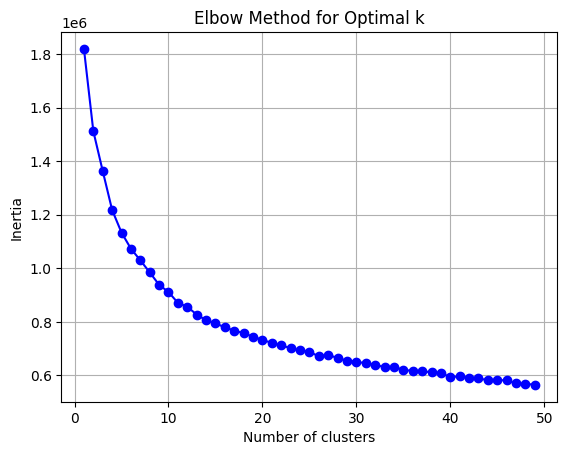

In [158]:
# Elbow plot
plt.plot(K, inertia, 'bo-')
plt.xlabel('Number of clusters')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal k')
plt.grid(True)
plt.show()

From the elbow plot above, choose 13 as the optimal K. Then, apply this value to the feature columns of the training set again, and select the feature in each cluster that is closest to each centroid.

In [159]:
# Apply K-means with K=13
kmeans = KMeans(n_clusters=13, random_state=999)
kmeans.fit(X_train.T)

KMeans(n_clusters=13, random_state=999)

In [160]:
# Centroids of the clusters
centroids = kmeans.cluster_centers_

# Extract the numerical values from the X_train DataFrame
df = X_train.T
a = df.values

# Find the features that are closest to the centroids
distances = np.linalg.norm(a - centroids[:, np.newaxis], axis=2)
closest_centroid_indices = np.argmin(distances, axis=1)
closest_feat = df.iloc[closest_centroid_indices]

# Display the selected indicators
closest_feat

Date,2017-04-25,2017-04-26,2017-04-27,2017-04-28,2017-05-01,2017-05-02,2017-05-03,2017-05-04,2017-05-05,2017-05-08,...,2022-07-29,2022-08-01,2022-08-02,2022-08-03,2022-08-04,2022-08-05,2022-08-08,2022-08-09,2022-08-10,2022-08-11
NVI_1_SPY_SPY,-1.324238,-1.324238,-1.323038,-1.323038,-1.323038,-1.322499,-1.322499,-1.320820,-1.320820,-1.321058,...,1.819787,1.815552,1.806117,1.806117,1.805151,1.805151,1.803491,1.797812,1.797812,1.797812
SMI_5_20_5_VGLT_VGLT,0.440927,0.274767,0.187721,0.162766,-0.124855,-0.218624,-0.212495,-0.339332,-0.391066,-0.586788,...,0.722557,0.980975,0.753692,0.796158,0.823918,0.472461,0.436922,0.358556,0.214571,-0.155337
VIDYA_14_XLE_XLE,-0.076876,-0.053260,-0.015180,0.017997,0.059663,0.098590,0.131239,0.155463,0.172693,0.181442,...,1.228483,1.234438,1.239228,1.235145,1.229493,1.226182,1.225026,1.224476,1.224333,1.232474
SMI_5_20_5_USO_USO,-1.026558,-1.140546,-1.226184,-1.281903,-1.388482,-1.623017,-1.749738,-2.094318,-1.984593,-1.910241,...,-0.264716,-0.392597,-0.411275,-0.578730,-0.800681,-0.935920,-0.849610,-0.800555,-0.691180,-0.449163
EMA_10_BIL_BIL,-1.437106,-1.376266,-1.409071,-1.270774,-1.322759,-1.447842,-1.550183,-1.551367,-1.634885,-1.620668,...,-0.881072,-1.169049,-1.363375,-1.563660,-1.644943,-1.628898,-1.574478,-1.571244,-1.527307,-1.491358
KCUe_20_2_SHY_SHY,-0.134517,-0.138679,-0.136973,-0.133865,-0.129490,-0.135694,-0.144435,-0.156251,-0.164597,-0.172149,...,-1.470109,-1.455730,-1.441937,-1.444313,-1.445679,-1.439098,-1.469102,-1.499375,-1.498624,-1.512796
SMI_5_20_5_SPY_SPY,0.103571,0.308365,0.455215,0.456117,0.523776,0.578025,0.554700,0.574343,0.707951,0.785177,...,0.711260,0.818313,0.776830,0.881907,0.935238,0.939454,0.920232,0.827991,0.975812,1.066551
SMI_5_20_5_BIL_BIL,0.331073,0.610546,0.267893,0.858953,0.348143,-0.221651,-0.525335,-0.381499,-0.571426,-0.377952,...,1.337929,-0.541595,-1.135170,-1.562470,-1.425919,-1.005347,-0.604256,-0.494200,-0.274341,-0.134760
NATR_14_VGLT_VGLT,-0.328788,-0.396461,-0.464344,-0.466323,-0.336077,-0.382162,-0.437612,-0.404643,-0.500118,-0.521635,...,0.981735,1.041453,1.359673,1.473392,1.220624,1.535971,1.395096,1.139977,1.170361,1.382018
CMO_14_XLE_XLE,-0.518838,-0.641183,-1.009738,-0.970935,-1.064699,-1.229810,-1.059808,-1.608695,-0.798672,-0.481312,...,0.857188,0.498028,0.458600,-0.002280,-0.491410,-0.209894,-0.135324,0.115762,0.219045,0.674080


Interestingly, the SMI_5_20_5 (Stochastic Momentum Index with periods 5, 20, and 5) indicators appear to represent 5 out of 13 clusters, while there are 4 SPY-related indicators that are representatives of the clusters.

Also add daily returns and month features to these 13 indicator set.

In [10]:
# Construct the feature matrices for the training and test sets
df = X_train

columns_to_keep = list(df.columns[:7])  # Create a list from the slice
columns_to_keep.extend(df.columns[-2:])
columns_to_keep.extend(['NVI_1_SPY_SPY', 'SMI_5_20_5_VGLT_VGLT', 'VIDYA_14_XLE_XLE',
                      'SMI_5_20_5_USO_USO', 'EMA_10_BIL_BIL', 'KCUe_20_2_SHY_SHY',
                      'SMI_5_20_5_SPY_SPY', 'SMI_5_20_5_BIL_BIL', 'NATR_14_VGLT_VGLT',
                      'CMO_14_XLE_XLE', 'SMI_5_20_5_GLD_GLD', 'PVI_1_SPY_SPY',
                      'PVO_12_26_9_SPY_SPY'])

X_train = X_train[columns_to_keep]
X_test = X_test[columns_to_keep]

### Correlation Check
Consider correlation among the selected features.

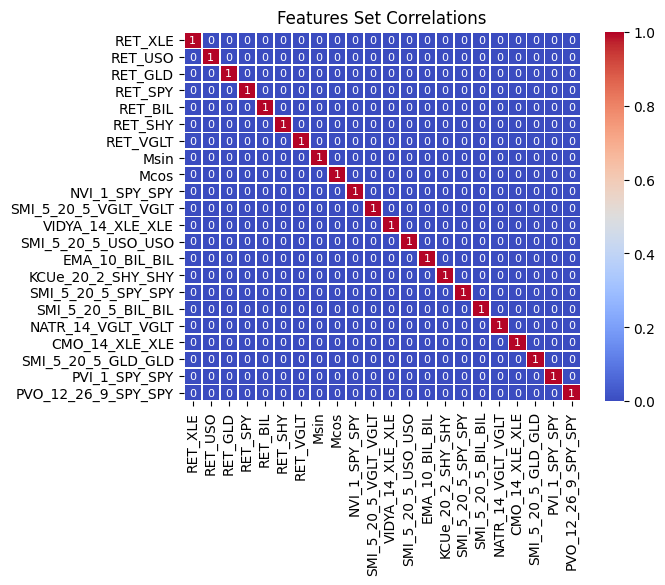

In [189]:
df = X_train

# Show pairs with very high correlation
sns.heatmap(df.corr()>0.8,
annot=True,
annot_kws={"size": 8},
linewidth=.5,
cmap="coolwarm",
cbar=True);

plt.title('Features Set Correlations');

There is no pair of features that is highly correlated, so the whole set of these features is used for the next step.

### Feature Importance
Due to the complexity of using SHAP with LSTM model, in this project, random forest with be used as a base estimator to determine feature importance. 

In [11]:
# Base estimator
est = RandomForestClassifier()
est.fit(X_train, y_train)

RandomForestClassifier()

The TreeExplainer performs on the training set only.

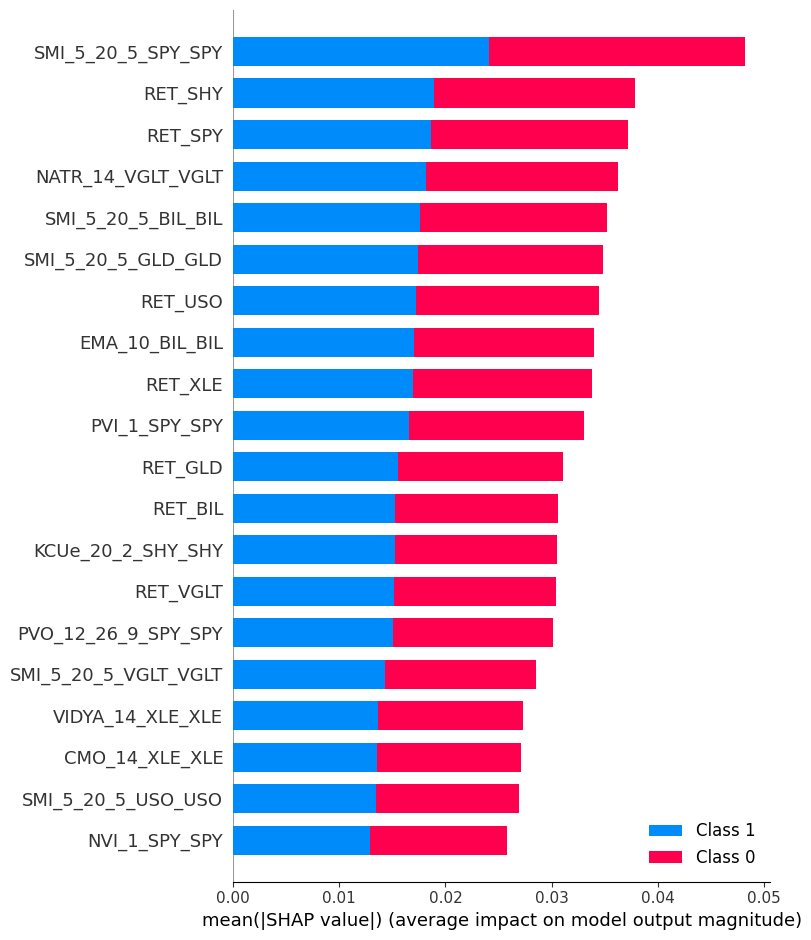

In [12]:
# Determine SHAP values
import shap

explainer = shap.TreeExplainer(est)
shap_values = explainer.shap_values(X_train)

# Interpretation plot
shap.summary_plot(shap_values, X_train)

The Stochastic Momentum Index (SMI) of SPY seems to be the most influential factor in predicting XLE's daily movement. This could be because XLE components are also included in SPY, meaning the overall momentum of SPY can indirectly affect XLE's daily fluctuations. While the average impact of each features are not much different, all features are kept.

In [168]:
# EDA on the final input matrix
X_train.describe().T

,count,mean,std,min,25%,50%,75%,max
RET_XLE,1280.0,-2.255141e-17,1.000391,-10.369606,-0.393578,0.016148,0.438238,6.848323
RET_USO,1280.0,-2.645453e-17,1.000391,-10.563301,-0.380817,0.071705,0.472886,5.591928
RET_GLD,1280.0,1.001803e-17,1.000391,-6.467659,-0.499323,0.031792,0.533632,5.488304
RET_SPY,1280.0,-1.631724e-17,1.000391,-9.121361,-0.320513,0.032991,0.451616,6.761032
RET_BIL,1280.0,-7.898630e-16,1.000391,-3.634530,-0.288710,-0.288710,0.547786,3.059485
RET_SHY,1280.0,-1.262011e-17,1.000391,-6.503406,-0.478326,-0.039125,0.409999,6.851968
RET_VGLT,1280.0,-3.469447e-18,1.000391,-7.763861,-0.550273,0.034996,0.552254,7.313659
Msin,1280.0,-3.632511e-16,1.000391,-1.413867,-0.826766,0.023367,0.741985,1.460602
Mcos,1280.0,4.544976e-16,1.000391,-1.290997,-1.103295,0.110028,0.810541,1.511054
NVI_1_SPY_SPY,1280.0,1.706968e-15,1.000391,-1.324758,-0.794251,-0.291179,1.017387,1.819787


## Models

In this project, LSTM or Long Short-Term Memory model is employed for uptrend prediction. It is a type of Recurrent Neural Network model that can handle sequential input data effectively. Each LSTM cell consists of
- Memory unit: to store information
- Forget gate: to delete information from the memory.
- Input gate: to add new information to the memory.
- Output gate: tosend out the output.

In [11]:
# Load the TensorBoard notebook extension
%load_ext tensorboard

In [12]:
# Create path to save the results
from pathlib import Path

results_path = Path('results', 'lstm_time_series')
if not results_path.exists():
    results_path.mkdir(parents=True)

### Base Model
First, construct the base model to be used as a benchmark.

#### Class Weights
Class imbalance can affect a model's performance. This issue is treated by using class weights.

In [13]:
# Check class frequency
c = np.bincount(y_train)
c

array([665, 615], dtype=int64)

The class frequencies in the training set are already quite balance, but to improve the model performance, class weights will be used.

In [14]:
from src.config import *

# Calculate class weights
class_weight = cwts(y_train)

# Check the class weights
class_weight[0] * c[0], class_weight[1] * c[1]

(640.0, 639.9999999999999)

#### Input Construction
Constuct 3D array input for LSTM model. Here, the sequence length of each data instance is set at 10 corresponding to 2-week-long time series.

In [15]:
# Sequence length
seqlen = 10

# Number of features
numfeat = X_train.shape[1]

# Generate train and test sequence input
g = TimeseriesGenerator(X_train, y_train, length=seqlen)
g_ = TimeseriesGenerator(X_test, y_test, length=seqlen)

#### Model Construction
Set the base model as a single hidden layer with 10 LSTM cells with 40% dropout. The ReLU and sigmoidal functions are utilzed as activation functions for the hidden and output layer, respectively.

In [16]:
# Set the random seed
set_seeds()

In [17]:
# Create a sequential model
def create_model(hu=20, lookback=10, features=1):
    
    tf.keras.backend.clear_session()   

    # Instantiate the model
    model = Sequential()
    
    model.add(LSTM(units=hu, input_shape=(lookback, features), activation = 'relu', return_sequences=False, name='LSTM1'))
    model.add(Dropout(0.4, name='Drouput1'))
    
    model.add(Dense(units=1, activation='sigmoid', name='Output'))             
    
    # Specify optimizer
    opt = Adam(lr=0.001, epsilon=1e-08, decay=0.0)       
    
    # model compilation - 'binary_crossentropy' - 'accuracy' - BinaryAccuracy(name='accuracy', threshold=0.5)
    model.compile(optimizer=opt, 
                  loss=BinaryCrossentropy(), 
                  metrics=['BinaryAccuracy', 
                           AUC()])

    return model

In [18]:
# Create the model
model = create_model(hu=10, lookback=seqlen, features=numfeat)

model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
LSTM1 (LSTM)                 (None, 10)                1320      
_________________________________________________________________
Drouput1 (Dropout)           (None, 10)                0         
_________________________________________________________________
Output (Dense)               (None, 1)                 11        
Total params: 1,331
Trainable params: 1,331
Non-trainable params: 0
_________________________________________________________________


In [19]:
# Specify callback functions
model_path = (results_path / 'model.h5').as_posix()
logdir = os.path.join("./tensorboard/logs", dt.datetime.now().strftime("%Y%m%d-%H%M%S"))

my_callbacks = [
    EarlyStopping(patience=10, monitor='loss', mode='min', verbose=1, restore_best_weights=True),
    ModelCheckpoint(filepath=model_path, verbose=1, monitor='loss', save_best_only=True),
    TensorBoard(log_dir=logdir, histogram_freq=1)
]

#### Model Training

In [ ]:
# Model fitting
model.fit(g,
          epochs=300, 
          verbose=1, 
          callbacks=my_callbacks, 
          shuffle=False,
          class_weight=class_weight)

#### Model Evaluation
The base model performance is evaluated by confusion matrix and AUC in both the training and the test set.

In [21]:
# Evaluate with the training set
y_true = y_train[-(len(X_train)-seqlen):]
y_pred = model.predict(g)  # Predicted probabilities

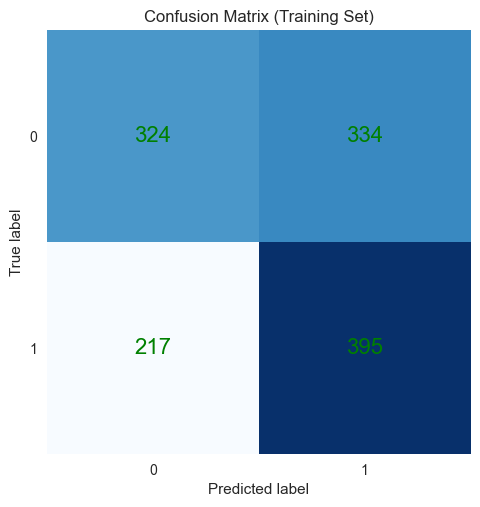

In [22]:
# Binary classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)

# Determine confusion matrix
cm = confusion_matrix(y_true, y_pred_cm)

# Plot the confusion matrix
fig, ax = plt.subplots()
ax.imshow(cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm.shape[0]): # Add number annotations for each cell
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="green", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Training Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()

In [23]:
# Classification report
print(classification_report(y_true, y_pred_cm))

              precision    recall  f1-score   support

           0       0.60      0.49      0.54       658
           1       0.54      0.65      0.59       612

    accuracy                           0.57      1270
   macro avg       0.57      0.57      0.56      1270
weighted avg       0.57      0.57      0.56      1270



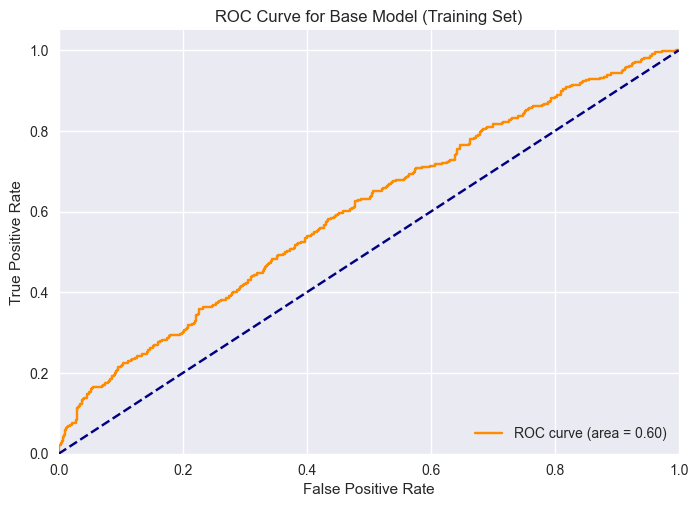

In [24]:
# Determine AUC
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Base Model (Training Set)')
plt.legend(loc="lower right")
plt.show()

Next, evaluate the model performance in the test set. 

In [25]:
# Evaluate with the test set
y_true = y_test[-(len(X_test)-seqlen):]
y_pred = model.predict(g_)  # Predicted probabilities

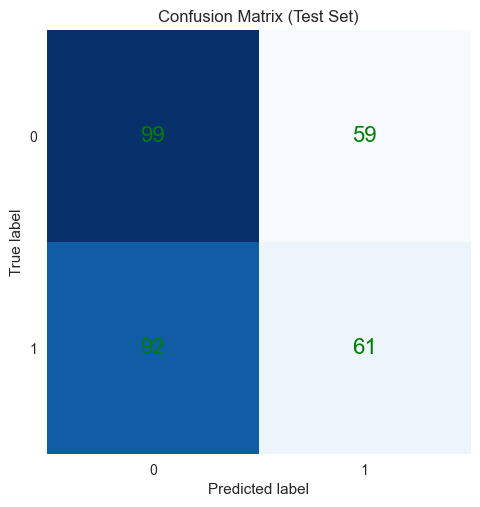

In [26]:
# Binary Classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)

# Store prediction
y_pred_base = y_pred_cm

cm = confusion_matrix(y_true, y_pred_cm)

# Binary classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)  

# Determine confusion matrix
cm = confusion_matrix(y_true, y_pred_cm)

# Plot the confusion matrix
fig, ax = plt.subplots()
ax.imshow(cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm.shape[0]): # Add number annotations for each cell
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="green", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()

In [27]:
# Classification report
print(classification_report(y_true, y_pred_cm))

              precision    recall  f1-score   support

           0       0.52      0.63      0.57       158
           1       0.51      0.40      0.45       153

    accuracy                           0.51       311
   macro avg       0.51      0.51      0.51       311
weighted avg       0.51      0.51      0.51       311



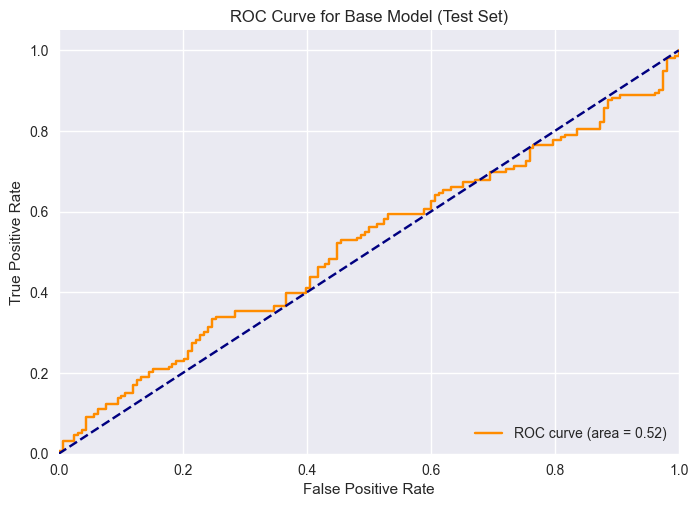

In [28]:
# Determine AUC
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Base Model (Test Set)')
plt.legend(loc="lower right")
plt.show()

Performance of the model in the test set obviously drops (AUC from 0.60 to 0.52, and F1-score from 0.56 to 0.51) indicating that the base model is somewhat overfitting.

## Hyperparameter Optimization
This step try to optimize hyperparameters of LSTM model to obtain the best result.

### Data Splitting
The training set is split further into the data for model training (75%) and for validation (25%), so that the test set remains untouched.

In [24]:
# Split the original training set into training and validation sets.
X_train1, X_val, y_train1, y_val = train_test_split(X_train, y_train, test_size=0.25, shuffle=False)

print(f"Train and Validation Size {len(X_train1)}, {len(X_val)}")

Train and Validation Size 960, 320


In [25]:
# 3D array input for LSTM model tuning
g1 = TimeseriesGenerator(X_train1, y_train1, length=seqlen)
g2 = TimeseriesGenerator(X_val, y_val, length=seqlen)

### Model Tuner Construction
LSTM model with 3 hidden layers is tuned for these hyperparameters:
- Number of cells in each layer $\in$ [5, 10, 15, 20]
- Dropout rate $\in$ [0.1, 0.2, 0.3, 0.4, 0.5]
- Learning rate $\in$ [0.01, 0.001, 0.0001]

In [26]:
def build_model(hp):
    
    tf.keras.backend.clear_session()   

    # Instantiate the model
    model = Sequential()
    
    # Tune the number of units in the layers
    hp_units1 = hp.Int('units1', min_value=5, max_value=20, step=5)
    hp_units2 = hp.Int('units2', min_value=5, max_value=20, step=5)
    hp_units3 = hp.Int('units3', min_value=5, max_value=20, step=5)
    
    # Tune the dropout rate
    hp_dropout1 = hp.Float('Dropout_rate1', min_value=0, max_value=0.5, step=0.1)
    hp_dropout2 = hp.Float('Dropout_rate2', min_value=0, max_value=0.5, step=0.1)

    # Tune the learning rate for the optimizer
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    
    model.add(LSTM(hp_units1, input_shape=(seqlen, numfeat), activation='relu', return_sequences=True, name='LSTM1'))   
    model.add(Dropout(hp_dropout1, name='Drouput1'))
    
    model.add(LSTM(hp_units2, activation = 'relu', return_sequences=True, name='LSTM2'))
    model.add(Dropout(hp_dropout2, name='Drouput2'))

    model.add(LSTM(hp_units3, activation = 'relu', return_sequences=False, name='LSTM3'))
    
    model.add(Dense(units=1, activation='sigmoid', name='Output'))    

    # Specify optimizer
    opt = Adam(lr=hp_learning_rate, epsilon=1e-08, decay=0.0)       
    
    # Model compilation
    model.compile(optimizer=opt, 
                  loss=BinaryCrossentropy(), 
                  metrics=['BinaryAccuracy', 
                           AUC()])

    return model

In [26]:
# Initialize an early stopping callback
callback1 = [EarlyStopping(patience=10, monitor='loss', mode='min', verbose=1, restore_best_weights=True),
             TensorBoard(log_dir="./tensorboard/rslogs")]

### Random Search
The hyperparameters are tuned by random search method from Keras Tuner. The number of trials is set at 200.

In [30]:
# RandomSearch algorithm from keras tuner
rstuner = RandomSearch(
    build_model,
    objective="val_binary_accuracy",
    max_trials=200,
    directory="./keras",
    project_name="rstrail",
    overwrite=True
)

In [31]:
# launch tuning process
rstuner.search(g1, epochs=300, validation_data=g2, callbacks=callback1, class_weight = class_weight, shuffle=False)

Trial 200 Complete [00h 00m 28s]
val_binary_accuracy: 0.5129032135009766

Best val_binary_accuracy So Far: 0.6000000238418579
Total elapsed time: 01h 11m 23s
INFO:tensorflow:Oracle triggered exit


In [32]:
# Display the best hyperparameter values for the model
best_rshp = rstuner.get_best_hyperparameters()[0]
print(best_rshp.values)

{'units1': 15, 'units2': 10, 'units3': 10, 'Dropout_rate1': 0.2, 'Dropout_rate2': 0.0, 'learning_rate': 0.0001}


The best hyperparameter values are as follows:
- 15, 10, and 10 cells in layers 1-3, respectively
- Dropout rate of 0.2 for the layer 1 only
- Learning rate of 0.0001

In [33]:
# display tuning results summary
rstuner.results_summary()

Results summary
Results in ./keras\rstrail
Showing 10 best trials
Objective(name='val_binary_accuracy', direction='max')
Trial summary
Hyperparameters:
units1: 15
units2: 10
units3: 10
Dropout_rate1: 0.2
Dropout_rate2: 0.0
learning_rate: 0.0001
Score: 0.6000000238418579
Trial summary
Hyperparameters:
units1: 15
units2: 15
units3: 5
Dropout_rate1: 0.2
Dropout_rate2: 0.0
learning_rate: 0.01
Score: 0.5806451439857483
Trial summary
Hyperparameters:
units1: 15
units2: 10
units3: 20
Dropout_rate1: 0.4
Dropout_rate2: 0.0
learning_rate: 0.001
Score: 0.5806451439857483
Trial summary
Hyperparameters:
units1: 5
units2: 10
units3: 10
Dropout_rate1: 0.1
Dropout_rate2: 0.4
learning_rate: 0.01
Score: 0.5774193406105042
Trial summary
Hyperparameters:
units1: 15
units2: 5
units3: 15
Dropout_rate1: 0.30000000000000004
Dropout_rate2: 0.4
learning_rate: 0.01
Score: 0.57419353723526
Trial summary
Hyperparameters:
units1: 10
units2: 20
units3: 10
Dropout_rate1: 0.0
Dropout_rate2: 0.1
learning_rate: 0.01
Sco

In [ ]:
#Visualize tuning process with TensorBoard
%tensorboard --logdir ./tensorboard/rslogs --reload_interval=0

### Training the Best Model
The best model is trained again with the whole original traning set. 

In [89]:
# Create a sequential model
def create_model_opt(lookback=60, features=1):
    
    tf.keras.backend.clear_session()   

    # instantiate the model
    model = Sequential()
    
    model.add(LSTM(units=15, input_shape=(lookback, features), activation = 'relu', return_sequences=True, name='LSTM1'))
    model.add(Dropout(0.2, name='Drouput1'))
    
    model.add(LSTM(units=10, activation = 'relu', return_sequences=True, name='LSTM2'))
    
    model.add(LSTM(units=10, activation = 'relu', return_sequences=False, name='LSTM3'))
    
    model.add(Dense(units=1, activation='sigmoid', name='Output'))             
    
    # specify optimizer separately (preferred method))
    opt = Adam(lr=0.0001, epsilon=1e-08, decay=0.0)       
    
    # model compilation - 'binary_crossentropy' - 'accuracy' - BinaryAccuracy(name='accuracy', threshold=0.5)
    model.compile(optimizer=opt, 
                  loss=BinaryCrossentropy(), 
                  metrics=['BinaryAccuracy', 
                           AUC()])

    return model

In [90]:
# Create the model
model = create_model_opt(lookback=seqlen, features=numfeat)

model.summary()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
LSTM1 (LSTM)                 (None, 10, 15)            2280      
_________________________________________________________________
Drouput1 (Dropout)           (None, 10, 15)            0         
_________________________________________________________________
LSTM2 (LSTM)                 (None, 10, 10)            1040      
_________________________________________________________________
LSTM3 (LSTM)                 (None, 10)                840       
_________________________________________________________________
Output (Dense)               (None, 1)                 11        
Total params: 4,171
Trainable params: 4,171
Non-trainable params: 0
_________________________________________________________________


In [91]:
# Specify callback functions
model_path = (results_path / 'model_opt.h5').as_posix()
logdir = os.path.join("./tensorboard/logs", dt.datetime.now().strftime("%Y%m%d-%H%M%S"))

my_callbacks = [
    EarlyStopping(patience=10, monitor='loss', mode='min', verbose=1, restore_best_weights=True),
    ModelCheckpoint(filepath=model_path, verbose=1, monitor='loss', save_best_only=True),
    TensorBoard(log_dir=logdir, histogram_freq=1)
]

In [ ]:
# Set the random seed
set_seeds()

# Model fitting
model.fit(g,
          epochs=300, 
          verbose=1, 
          callbacks=my_callbacks, 
          shuffle=False,
          class_weight=class_weight)

### Evaluating the Best Model
Evaluate with the training set first.

In [93]:
# Evaluate with the training set
y_true = y_train[-(len(X_train)-seqlen):]
y_pred = model.predict(g)  # Predicted probabilities

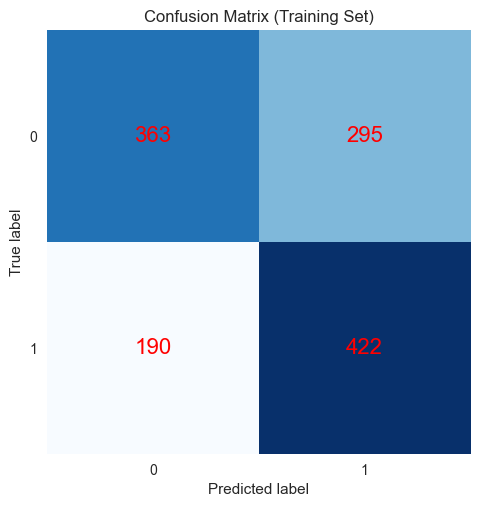

In [95]:
# Binary classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)

# Determine confusion matrix
cm = confusion_matrix(y_true, y_pred_cm)

# Plot the confusion matrix
fig, ax = plt.subplots()
ax.imshow(cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm.shape[0]): # Add number annotations for each cell
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="red", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Training Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])

plt.show()

In [96]:
# Classification report
print(classification_report(y_true, y_pred_cm))

              precision    recall  f1-score   support

           0       0.66      0.55      0.60       658
           1       0.59      0.69      0.64       612

    accuracy                           0.62      1270
   macro avg       0.62      0.62      0.62      1270
weighted avg       0.62      0.62      0.62      1270



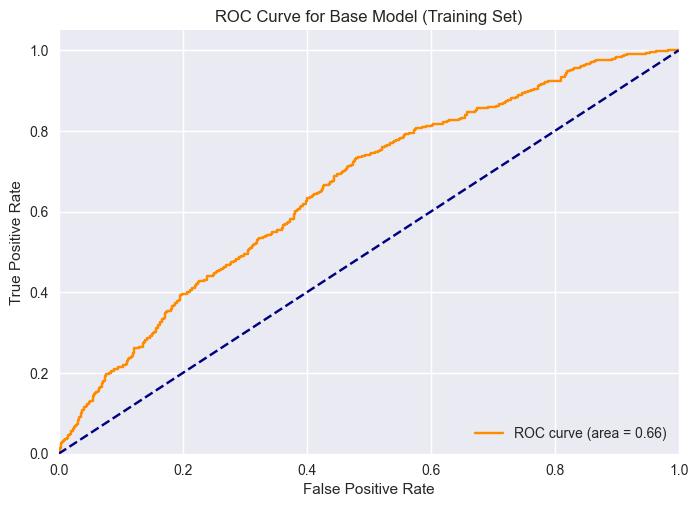

In [97]:
# Determine AUC
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Base Model (Training Set)')
plt.legend(loc="lower right")
plt.show()

In the training set, comparing with the base model, performance of the optimized model is slightly improved (F1-score: 0.62 vs 0.56, AUC: 0.66 vs 0.60). 

Next, the optimized model is evaluated with the unseen test set.

In [98]:
# Evaluate with the test set
y_true = y_test[-(len(X_test)-seqlen):]
y_pred = model.predict(g_)  # Predicted probabilities

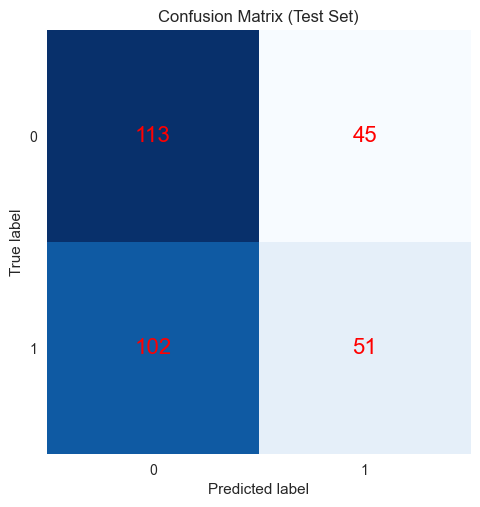

In [102]:
# Binary Classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)

# Store prediction
y_pred_opt = y_pred_cm

cm = confusion_matrix(y_true, y_pred_cm)

# Binary classification
y_pred_cm = np.where(y_pred > 0.5, 1, 0)  

# Determine confusion matrix
cm = confusion_matrix(y_true, y_pred_cm)

# Plot the confusion matrix
fig, ax = plt.subplots()
ax.imshow(cm, cmap=plt.cm.Blues)
ax.grid(False)

for i in range(cm.shape[0]): # Add number annotations for each cell
    for j in range(cm.shape[1]):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="red", fontsize=16)

# Add labels and title
plt.title('Confusion Matrix (Test Set)')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.xticks(np.arange(2), [0, 1])
plt.yticks(np.arange(2), [0, 1])
plt.show()

In [100]:
# Classification report
print(classification_report(y_true, y_pred_cm))

              precision    recall  f1-score   support

           0       0.53      0.72      0.61       158
           1       0.53      0.33      0.41       153

    accuracy                           0.53       311
   macro avg       0.53      0.52      0.51       311
weighted avg       0.53      0.53      0.51       311



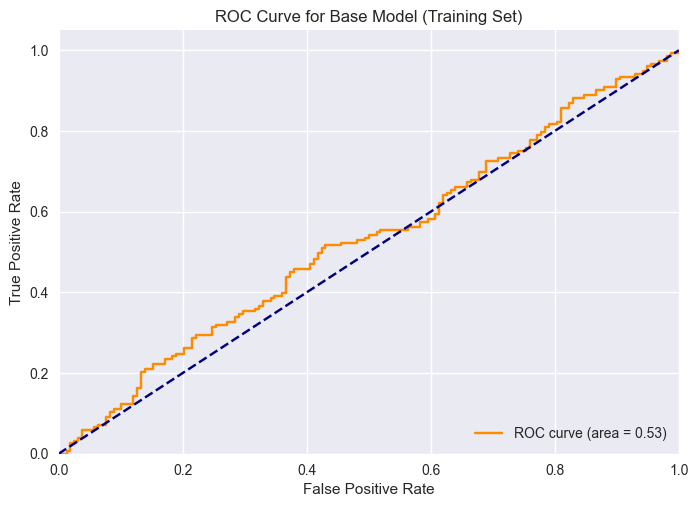

In [101]:
# Determine AUC
fpr, tpr, thresholds = roc_curve(y_true, y_pred)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure()
plt.plot(fpr, tpr, color='darkorange', label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve for Base Model (Training Set)')
plt.legend(loc="lower right")
plt.show()

In the unseen test set, the performance of the base and optimized models is not different. The sharp drop of performance also demonstrate that the optimized model is highly overfitting. While fixing the number of hidden layers at 3 during random search, the model's increasing parameters may heighten overfitting risk, especially given the small training set. To improve model performance, a number of hidden layers should be varied in the optimization process, too. Furthermore, the random search was performed only 200 trials, which could cover less than 5% of hyperparameter combination space. Increasing a number os trials or employing Bayesian optimization instead might enhance the result. 

## Backtesting
The models in this work predict the uptrend at least 0.1% on the next day, so the strategy used for backtesting is long-only. Starting with $1, the strategy buys XLE with all remaining capital if the model predicts an uptrend for the next day's return; otherwise, it does nothing. For calculation simplicity, assume it always buys at today's close and get out of the position at tomorrow's close. Note that this strategy is not practical because buying the ETF after a prediction based on today's close simply isn't feasible in live markets. The strategy is backtested the strategy on data in a hold-out test set between 29 August 2022 and 21 November 2023.

In [157]:
#Build dataframe for backtesting
df = pd.DataFrame(scaler.inverse_transform(X_test_scaled), index=X_test_scaled.index, columns=X_test_scaled.columns)
bt = pd.DataFrame(df['RET_XLE'][-(len(X_test)-seqlen):])

# Add prediction columns
bt['Base_pred'] = y_pred_base # Prediction from the base model
bt['Opt_pred'] = y_pred_opt # Prediction from the optimized model

# Add strategy columns by shifting the prediction columns one step forward
bt['Strat_base'] = bt['Base_pred'].shift(1)
bt['Strat_opt'] = bt['Opt_pred'].shift(1)

# Daily returns of strategies
bt['Strat_RET_base'] = bt['RET_XLE'] * bt['Strat_base']
bt['Strat_RET_opt'] = bt['RET_XLE'] * bt['Strat_opt']
bt.iloc[0, [0, 5, 6]] = 0

# Backtest dataframe
bt

,RET_XLE,Base_pred,Opt_pred,Strat_base,Strat_opt,Strat_RET_base,Strat_RET_opt
Date,,,,,,,
2022-08-26,0.000000,0,0,NaN,NaN,0.000000,0.0
2022-08-29,0.014977,0,0,0.0,0.0,0.000000,0.0
2022-08-30,-0.034480,0,0,0.0,0.0,-0.000000,-0.0
2022-08-31,-0.009150,1,0,0.0,0.0,-0.000000,-0.0
2022-09-01,-0.024904,1,0,1.0,0.0,-0.024904,-0.0
...,...,...,...,...,...,...,...
2023-11-15,-0.001890,1,0,1.0,0.0,-0.001890,-0.0
2023-11-16,-0.019696,1,0,1.0,0.0,-0.019696,-0.0
2023-11-17,0.020760,1,0,1.0,0.0,0.020760,0.0


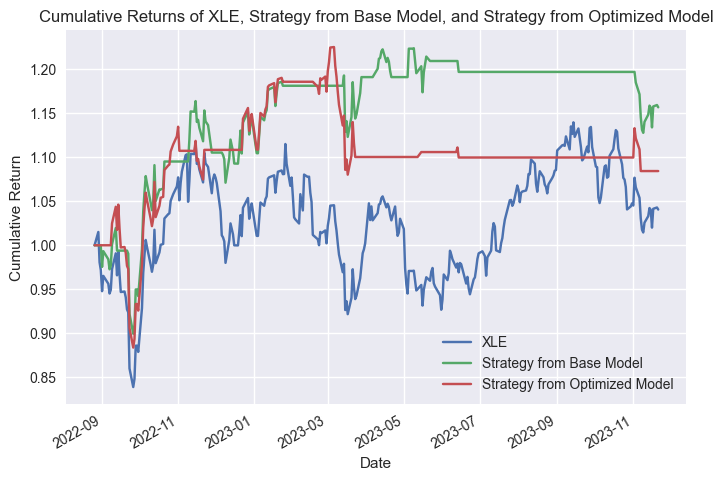

In [164]:
# Plot and compare P&L
#bt[['RET_XLE', 'Strat_RET_base', 'Strat_RET_opt']].cumsum().apply(np.exp).plot()
ax = bt[['RET_XLE', 'Strat_RET_base', 'Strat_RET_opt']].cumsum().apply(np.exp).plot()

plt.title("Cumulative Returns of XLE, Strategy from Base Model, and Strategy from Optimized Model")
plt.ylabel("Cumulative Return")

plt.legend(labels=["XLE", "Strategy from Base Model", "Strategy from Optimized Model"])

plt.show()

From the plot of cumulative returns comparing among strategies from both models and buy-and-hold, it appears that the performance of both stategy is better than buy-and-hold. This might be because both models achieve high recall for class 0 (63% for base, 72% for optimized), enabling them to avoid negative return days. However, their recalls for uptrend days (class 1) are low (40% base, 33% optimized). This missed opportunity likely contributes to the optimized model's lower return. However, these strategy performance figures exclude transaction fees, which would decrease returns in real trading, potentially even below buy-and-hold. Further investigation is required.

## Discussion and Conclusion
This project aimed to predict the next day's uptrend for the XLE ETF, which represents the energy sector of the S&P 500, using LSTM models. The input were historical prices from various asset class ETFs. After engineering and selecting relevant features, the base model was built. Then, random search was employed to optimize its architecture. While both models outperformed random prediction slightly, their accuracy was not significantly different on the hold-out dataset. Next, trading strategies were developed based on these models, and backtesting revealed their performance exceeded a simple buy-and-hold approach.

However, both strategies require further development to ensure feasibility in live trading. One key factor missing here is transaction fees, which could significantly impact their performance. Other than that, there is still room for potential model and strategy improvement:
- Modifying the prediction target: Predicting the next day's open-to-close price difference could offer more feasible trading than what had been done here.
- Adjusting the prediction period: Given the relatively high short-term fluctuations in daily returns, exploring longer-term prediction horizons might be more valuable.
- Integrating additional data: Including relevant fundamental factors like crude oil production, reserves, and demand might enhance the models' forecasting power for longer periods.
- Handling categorical indicators: Some engineered technical indicators currently treated as numerical might actually be categorical. Properly identifying and handling these could provide more insights for the model.
- LSTM-specific feature importance: While a random forest is used to assess feature importance, directly determining it within the LSTM itself could lead to a more effective feature selection process.

Moreover, other than the fixed hidden layer issue already mentioned, there are another two areas that could be considered for hyperparameter optimization:
- Class weight leakage: Currently, the class weight calculation incorporates the entire training data, including the validation set. This introduces information leakage and biases the model. A more appropriate approach would be to compute the class weight solely from the actual training data used for model fitting.
- Weight initialization: Model performance was found to be significantly influenced by weight initialization. Implementing advanced techniques like He or Xavier initialization could potentially lead to improved model performance.

## Appendix
The following table displays the numerical techniques utilized in this work.

| Technique | Purpose |
|---|---|
| Exploratory Data Analysis | Initial data investigation |
| Feature Engineering (pandas-ta) | Create technical indicators for model input |
| Categorical Data Transformation | Encode month index using sin/cos functions|
| Standardization | Scale features to equal range for model stability |
| K-means Clustering | Reduce feature dimensionality and select relevant features |
| Pearson Correlation | Analyze correlations between features for selection |
| Shapley Value | Measure feature importance for selection |
| LSTM Model | Predict uptrend of XLE ETF |
| Class Weight | Handle class imbalance in training data |
| Confusion Matrix | Visualize model performance for each class |
| Classification Report | Evaluate model precision, recall, and F1 score |
| ROC and AUC | Assess model performance based on false positive and true positive rates |
| Random Search | Optimize hyperparameters of the LSTM model |
| Backtesting | Evaluate trading strategies based on model predictions |